# Predicting Diabetes Disease Progression

Can we predict how much a patient's diabetes progresses over one year from ten baseline measurements? This notebook compares linear regression with XGBoost on the scikit-learn diabetes dataset (442 patients).

Steps:
1. Fit a linear model on each feature by itself.
2. Try every pair of features (45 pairs).
3. Fit linear regression and XGBoost on all ten features.
4. Check how training-set size affects overfitting with a learning curve.

All scores are on a held-out test set or from 5-fold cross-validation, never on training data.

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score, learning_curve, KFold
from sklearn.metrics import mean_squared_error, r2_score
from xgboost import XGBRegressor

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Load the data

In [2]:
data = load_diabetes(as_frame=True)
df = data.frame
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [3]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
age,442.0,-0.000,0.048,-0.107,-0.037,0.005,0.038,0.111
sex,442.0,0.000,0.048,-0.045,-0.045,-0.045,0.051,0.051
bmi,442.0,-0.000,0.048,-0.090,-0.034,-0.007,0.031,0.171
bp,442.0,-0.000,0.048,-0.112,-0.037,-0.006,0.036,0.132
s1,442.0,-0.000,0.048,-0.127,-0.034,-0.004,0.028,0.154
s2,442.0,0.000,0.048,-0.116,-0.030,-0.004,0.030,0.199
s3,442.0,-0.000,0.048,-0.102,-0.035,-0.007,0.029,0.181
s4,442.0,-0.000,0.048,-0.076,-0.039,-0.003,0.034,0.185
s5,442.0,0.000,0.048,-0.126,-0.033,-0.002,0.032,0.134
s6,442.0,0.000,0.048,-0.138,-0.033,-0.001,0.028,0.136


The features are already mean-centered and scaled. The target is a quantitative measure of disease progression one year after baseline.

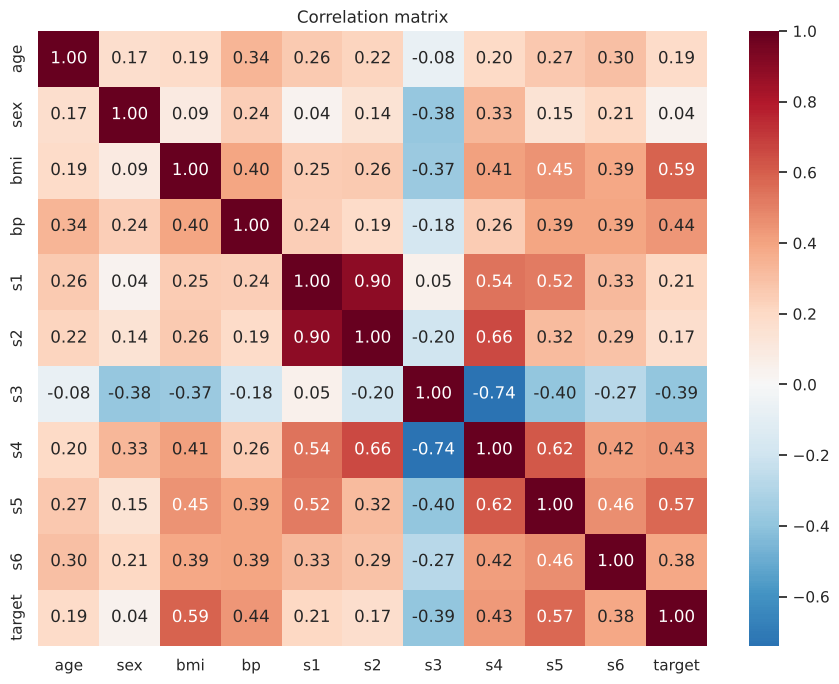

In [4]:
corr = df.corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation matrix")
plt.tight_layout(); plt.savefig("images/correlation_matrix.png", dpi=120); plt.show()

In [5]:
X, y = df.drop(columns="target"), df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
len(X_train), len(X_test)

(353, 89)

## 2. One feature at a time

Cross-validated MSE for a linear model on each feature alone (training set only).

In [6]:
def cv_mse(model, cols):
    return -cross_val_score(model, X_train[cols], y_train, cv=cv, scoring="neg_mean_squared_error").mean()

single = pd.Series({c: cv_mse(LinearRegression(), [c]) for c in X.columns}).sort_values()
single.round(1).to_frame("CV MSE")

,CV MSE
bmi,3909.2
s5,4301.7
bp,4912.4
s4,5044.3
s6,5255.8
s3,5311.4
s1,5893.8
age,5933.1
s2,6007.6
sex,6226.3


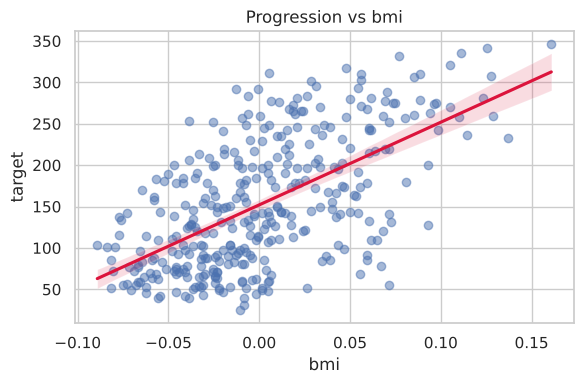

In [7]:
best = single.index[0]
plt.figure(figsize=(6, 4))
sns.regplot(x=X_train[best], y=y_train, line_kws={"color": "crimson"}, scatter_kws={"alpha": 0.5})
plt.title(f"Progression vs {best}")
plt.tight_layout(); plt.savefig("images/best_single_feature.png", dpi=120); plt.show()

## 3. Every pair of features

In [8]:
pairs = pd.Series({f"{a} + {b}": cv_mse(LinearRegression(), [a, b])
                   for a, b in itertools.combinations(X.columns, 2)}).sort_values()
print(f"{len(pairs)} pairs tested")
pairs.head(10).round(1).to_frame("CV MSE")

45 pairs tested


,CV MSE
bmi + s5,3359.0
bmi + bp,3612.2
bmi + s4,3722.5
bmi + s3,3742.1
bmi + s6,3792.8
bp + s5,3897.0
age + bmi,3899.5
bmi + s1,3910.0
bmi + s2,3922.9
sex + bmi,3952.1


In [9]:
improvement = (single.iloc[0] - pairs.iloc[0]) / single.iloc[0] * 100
print(f"Best pair ({pairs.index[0]}) lowers CV MSE by {improvement:.1f}% versus {single.index[0]} alone")

Best pair (bmi + s5) lowers CV MSE by 14.1% versus bmi alone


## 4. All ten features: linear regression vs XGBoost

In [10]:
xgb = XGBRegressor(n_estimators=300, max_depth=2, learning_rate=0.05, subsample=0.8,
                   colsample_bytree=0.8, random_state=RANDOM_STATE)
models = {"Linear regression": LinearRegression(), "XGBoost": xgb}
rows = []
for name, m in models.items():
    cv_score = cv_mse(m, list(X.columns))
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    rows.append({"model": name, "CV MSE": cv_score,
                 "Test MSE": mean_squared_error(y_test, pred), "Test R2": r2_score(y_test, pred)})
results = pd.DataFrame(rows).set_index("model").round(3)
results

,CV MSE,Test MSE,Test R2
model,,,
Linear regression,3074.142,2900.194,0.453
XGBoost,3490.231,2939.598,0.445


On a dataset this small, a tuned linear model is hard to beat. XGBoost's extra flexibility does not buy much, because most of the signal is roughly linear in BMI, S5 and blood pressure.

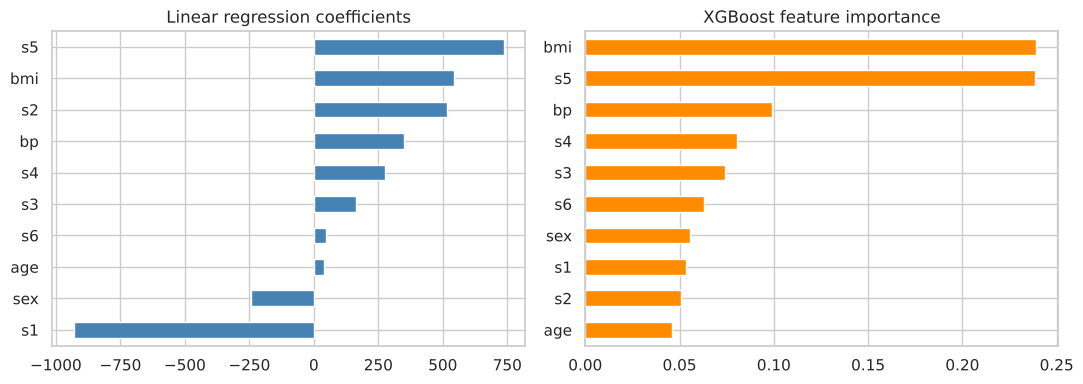

In [11]:
lin = models["Linear regression"]
coef = pd.Series(lin.coef_, index=X.columns).sort_values()
imp = pd.Series(models["XGBoost"].feature_importances_, index=X.columns).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
coef.plot.barh(ax=ax[0], color="steelblue"); ax[0].set_title("Linear regression coefficients")
imp.plot.barh(ax=ax[1], color="darkorange"); ax[1].set_title("XGBoost feature importance")
plt.tight_layout(); plt.savefig("images/feature_importance.png", dpi=120); plt.show()

## 5. Learning curve: how much data do we need?

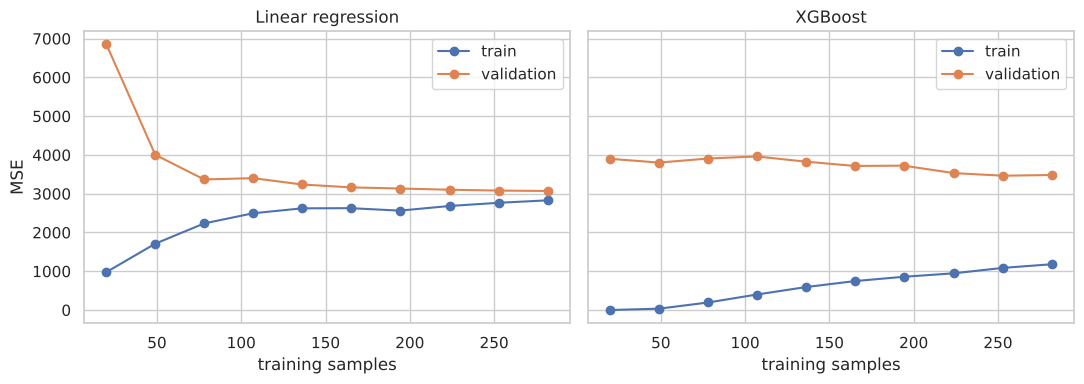

In [12]:
sizes = np.linspace(20, len(X_train) * 0.8, 10).astype(int)
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, (name, m) in zip(ax, models.items()):
    n, tr, va = learning_curve(m, X_train, y_train, train_sizes=sizes, cv=cv,
                               scoring="neg_mean_squared_error", random_state=RANDOM_STATE)
    a.plot(n, -tr.mean(1), "o-", label="train"); a.plot(n, -va.mean(1), "o-", label="validation")
    a.set_title(name); a.set_xlabel("training samples"); a.legend()
ax[0].set_ylabel("MSE")
plt.tight_layout(); plt.savefig("images/learning_curve.png", dpi=120); plt.show()

## Takeaways

- BMI is the strongest single predictor, and adding S5 (a blood serum measure) gives the biggest gain of any pair.
- With all ten features, linear regression and XGBoost score close to each other on held-out data. The simpler model is easier to explain to clinicians, so it is the better choice here.
- Linear regression overfits badly below about 80 training samples, then its training and validation errors settle close together.
- XGBoost keeps a large gap between training and validation error at every sample size. Its training error can look excellent (near zero), which is why model comparisons must use held-out data.